# Contract-Risk-AI: Contract Clause Risk Classification

Classifies contract clauses into **High / Medium / Low** risk groups with two approaches: TF-IDF + Logistic Regression and an LSTM.

> **Important:** the risk groups are an *experimental mapping* of LEDGAR provision labels created for this project. They are not legally validated risk assessments, and the model output is not legal advice.

**Workflow:** data preparation and cleaning → exploratory analysis → Model 1 (TF-IDF + Logistic Regression) → Model 2 (LSTM) → comparison.

Written for Google Colab. Code and saved outputs come from the original run; only markdown cells were added and a few comments were tidied in this copy.

## 1. Setup
Installs the Hugging Face `datasets` library, pandas and matplotlib. The other libraries used later (scikit-learn, NLTK, TensorFlow, seaborn, wordcloud) are listed in `requirements.txt`.

In [ ]:
!pip install datasets pandas matplotlib


## 2. Data preparation
- Loads the train split of `coastalchp/ledgar` (60,000 labelled contract clauses; LEDGAR provision labels).
- Maps 72 label IDs to High (13), Medium (27) or Low (32) with a hand-written dictionary. Clauses with any other label are dropped, leaving **49,282 clauses** (Low 23,771 / Medium 19,071 / High 6,440).
- Cleaning: lowercase, remove digits and punctuation, remove English stop words, WordNet lemmatization.
- Writes `final_preprocessed_data.csv` (generated file, not committed to the repository).

In [ ]:
import pandas as pd
from datasets import load_dataset
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# 1. Setup NLP tools
nltk.download('stopwords')
nltk.download('wordnet')
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# 2. Load dataset
print("Loading LEDGAR dataset...")
raw_dataset = load_dataset("coastalchp/ledgar", split='train')
df = pd.DataFrame(raw_dataset)

# 3. Risk mapping: LEDGAR label ID -> experimental High/Medium/Low group
risk_mapping = {
    # High Risk
    49: 'High', 17: 'High', 81: 'High', 44: 'High', 27: 'High',
    30: 'High', 36: 'High', 37: 'High', 23: 'High', 58: 'High',
    88: 'High', 75: 'High', 62: 'High',
    # Medium Risk
    47: 'Medium', 7: 'Medium', 20: 'Medium', 19: 'Medium', 43: 'Medium',
    11: 'Medium', 10: 'Medium', 31: 'Medium', 42: 'Medium', 9: 'Medium',
    16: 'Medium', 12: 'Medium', 15: 'Medium', 6: 'Medium', 4: 'Medium',
    5: 'Medium', 21: 'Medium', 3: 'Medium', 51: 'Medium', 87: 'Medium',
    85: 'Medium', 76: 'Medium', 98: 'Medium', 53: 'Medium', 80: 'Medium',
    86: 'Medium', 99: 'Medium',
    # Low Risk
    26: 'Low', 38: 'Low', 2: 'Low', 41: 'Low', 45: 'Low', 46: 'Low',
    13: 'Low', 48: 'Low', 29: 'Low', 18: 'Low', 24: 'Low', 33: 'Low',
    22: 'Low', 32: 'Low', 28: 'Low', 0: 'Low', 39: 'Low', 35: 'Low',
    40: 'Low', 1: 'Low', 34: 'Low', 8: 'Low', 14: 'Low', 65: 'Low',
    79: 'Low', 89: 'Low', 97: 'Low', 90: 'Low', 59: 'Low', 84: 'Low',
    73: 'Low', 52: 'Low'
}

df['risk_level'] = df['label'].map(risk_mapping)
df_final = df.dropna(subset=['risk_level']).copy()

# 4. Advanced Preprocessing Function
def advanced_cleaning(text):
    # Basic Cleaning
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)

    # Tokenization and removing Stop words + Lemmatization
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]

    return " ".join(words)

print("Applying advanced cleaning (Stop words & Lemmatization)...")
df_final['cleaned_text'] = df_final['text'].apply(advanced_cleaning)

# 5. Final Report Summary
print("\n--- DATASET READY FOR TRAINING ---")
print(f"Total classified clauses: {len(df_final)}")
print("\nClass Distribution:")
print(df_final['risk_level'].value_counts())

# Save to CSV for the team
df_final.to_csv('final_preprocessed_data.csv', index=False)
print("\nFile 'final_preprocessed_data.csv' has been created.")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


Loading LEDGAR dataset...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/16.0M [00:00<?, ?B/s]

...

data/validation-00000-of-00001.parquet:   0%|          | 0.00/2.65M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/60000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Applying advanced cleaning (Stop words & Lemmatization)...

--- DATASET READY FOR TRAINING ---
Total classified clauses: 49282

Class Distribution:
risk_level
Low       23771
Medium    19071
High       6440
Name: count, dtype: int64

File 'final_preprocessed_data.csv' has been created.


## 3. Exploratory analysis
Top-20 original provision labels, the resulting risk-class distribution, and a word cloud of the first 10,000 cleaned clauses.

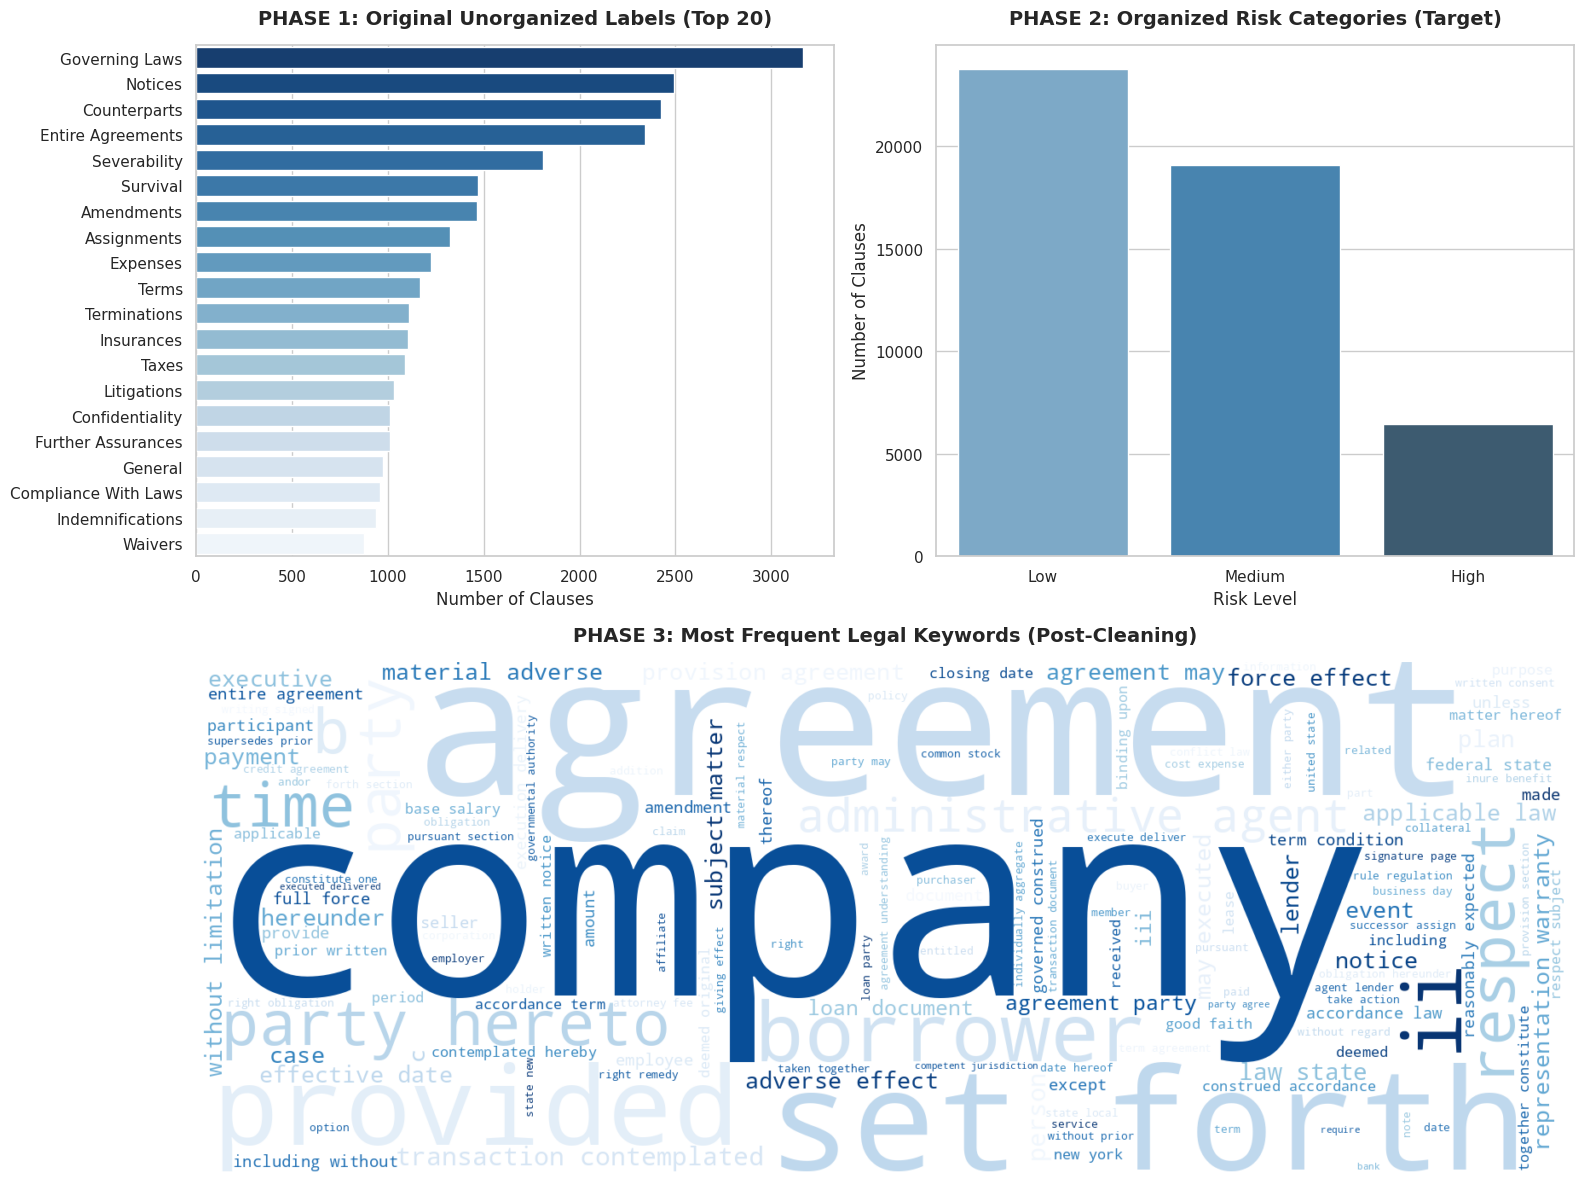

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import matplotlib.gridspec as gridspec

# 1. Standardizing the Setup
sns.set(style="whitegrid")
plt.rcParams['figure.dpi'] = 100 # Keep it clear and stable

# Get label names from the raw_dataset features
# This assumes raw_dataset is available from previous cells.
# If raw_dataset is not defined, we would need to reload it or pass it.
# Based on the kernel state, df and df_final are available, which means raw_dataset was loaded.
# The `df` variable's `label` column is `int64`, so `raw_dataset.features['label']` is the correct source.
names = raw_dataset.features['label'].names

# 2. Creating the Figure correctly to avoid the "jumping/shaking" issue
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(2, 2, height_ratios=[1, 1])

# --- PHASE 1: Original Labels ---
ax0 = plt.subplot(gs[0, 0])
top_original = df['label'].value_counts().head(20)
# Use names[i] to get the actual text names for the Y-axis
label_names = [names[i] for i in top_original.index]

sns.barplot(x=top_original.values, y=label_names, ax=ax0,
            palette="Blues_r", hue=label_names, legend=False)
ax0.set_title('PHASE 1: Original Unorganized Labels (Top 20)', fontsize=14, fontweight='bold', pad=15)
ax0.set_xlabel('Number of Clauses')

# --- PHASE 2: Risk Categories ---
ax1 = plt.subplot(gs[0, 1])
sns.countplot(x='risk_level', data=df_final, ax=ax1, palette="Blues_d",
              order=['Low', 'Medium', 'High'], hue='risk_level', legend=False)
ax1.set_title('PHASE 2: Organized Risk Categories (Target)', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Risk Level')
ax1.set_ylabel('Number of Clauses')

# --- PHASE 3: Word Cloud ---
ax2 = plt.subplot(gs[1, :])
all_text = ' '.join(df_final['cleaned_text'].iloc[:10000])
wordcloud = WordCloud(width=1600, height=600, background_color='white',
                      colormap='Blues', max_words=150).generate(all_text)
ax2.imshow(wordcloud, interpolation='bilinear')
ax2.axis('off')
ax2.set_title('PHASE 3: Most Frequent Legal Keywords (Post-Cleaning)', fontsize=14, fontweight='bold', pad=15)

# Finalizing the layout
plt.tight_layout()
plt.show()

## 4. Model 1: TF-IDF + Logistic Regression
Stratified 80/20 split (`random_state=42`: 39,425 training / 9,857 test clauses), `TfidfVectorizer(max_features=5000)` fitted on the training set, and `LogisticRegression(class_weight='balanced', max_iter=1000)`.

Saved result: accuracy 0.92; for the High class, precision 0.81 and recall 0.92 (support 1,288).

Success: df_final found in memory.

--- MACHINE LEARNING MODEL PERFORMANCE ---
Accuracy Score: 0.92

Classification Report:

              precision    recall  f1-score   support

        High       0.81      0.92      0.86      1288
         Low       0.95      0.91      0.93      4755
      Medium       0.93      0.93      0.93      3814

    accuracy                           0.92      9857
   macro avg       0.89      0.92      0.91      9857
weighted avg       0.92      0.92      0.92      9857



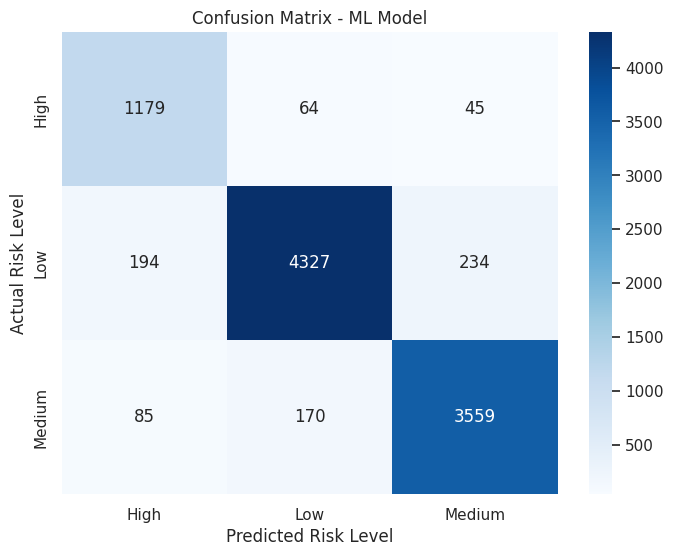

In [ ]:
# --- START OF MACHINE LEARNING PHASE ---
# Model 1: TF-IDF + Logistic Regression

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# التأكد من وجود البيانات في الذاكرة
try:
    X = df_final['cleaned_text']
    y = df_final['risk_level']
    print("Success: df_final found in memory.")
except NameError:
    print("df_final not found! Reading from the CSV file instead...")
    import pandas as pd
    df_final = pd.read_csv('final_preprocessed_data.csv')
    X = df_final['cleaned_text']
    y = df_final['risk_level']

# 1. تقسيم البيانات (80% تدريب و 20% اختبار)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. تحويل النصوص إلى أرقام (Feature Extraction)
tfidf = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

# 3. بناء وتدريب موديل Logistic Regression
ml_model = LogisticRegression(max_iter=1000, class_weight='balanced')
ml_model.fit(X_train_tfidf, y_train)

# 4. Predict on the test set and report metrics
y_pred = ml_model.predict(X_test_tfidf)

print("\n" + "="*40)
print("--- MACHINE LEARNING MODEL PERFORMANCE ---")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))
print("="*40)

# 5. رسم مصفوفة الارتباك (Confusion Matrix)
plt.figure(figsize=(8,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=ml_model.classes_,
            yticklabels=ml_model.classes_)
plt.title('Confusion Matrix - ML Model')
plt.ylabel('Actual Risk Level')
plt.xlabel('Predicted Risk Level')
plt.show()


## 5. Model 2: LSTM and comparison
Reloads and re-cleans the data independently, then trains an LSTM on the same split parameters (same class supports).

- Keras `Tokenizer` (20,000 words), sequences padded to 200 tokens.
- Embedding(128) → LSTM(128, dropout 0.3, recurrent dropout 0.3) → Dense(64, ReLU) → Dropout(0.5) → Dense(3, softmax).
- Adam, sparse categorical cross-entropy, 5 epochs, batch size 64, `validation_split=0.1`.

Saved result: accuracy 0.9258; for the High class, precision 0.89 and recall 0.84. The comparison printout at the end uses a hard-coded 0.92 for Logistic Regression instead of the computed value. Each model was run once, so the small difference should not be over-interpreted.

🚀 جاري تحميل المكتبات...

📥 جاري تحميل بيانات LEDGAR...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/16.0M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/2.54M [00:00<?, ?B/s]

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


🚀 بدء التدريب (سيستغرق 5-10 دقائق)...
Epoch 1/5
555/555 ━━━━━━━━━━━━━━━━━━━━ 232s 410ms/step - accuracy: 0.8185 - loss: 0.4980 - val_accuracy: 0.8930 - val_loss: 0.3304
Epoch 2/5
555/555 ━━━━━━━━━━━━━━━━━━━━ 222s 401ms/step - accuracy: 0.8987 - loss: 0.3252 - val_accuracy: 0.9163 - val_loss: 0.2532
Epoch 3/5
555/555 ━━━━━━━━━━━━━━━━━━━━ 258s 393ms/step - accuracy: 0.9244 - loss: 0.2562 - val_accuracy: 0.9199 - val_loss: 0.2403
Epoch 4/5
555/555 ━━━━━━━━━━━━━━━━━━━━ 226s 407ms/step - accuracy: 0.9304 - loss: 0.2386 - val_accuracy: 0.9254 - val_loss: 0.2207
Epoch 5/5
555/555 ━━━━━━━━━━━━━━━━━━━━ 266s 414ms/step - accuracy: 0.9412 - loss: 0.1982 - val_accuracy: 0.9308 - val_loss: 0.2148

📊 جاري تقييم النموذج...
309/309 ━━━━━━━━━━━━━━━━━━━━ 18s 56ms/step

🎯 دقة LSTM: 0.9258 (92.58%)

📋 تقرير التصنيف:
              precision    recall  f1-score   support

        High       0.89      0.84      0.87      1288
         Low       0.94      0.93      0.94      4755
      Medium       0.92     

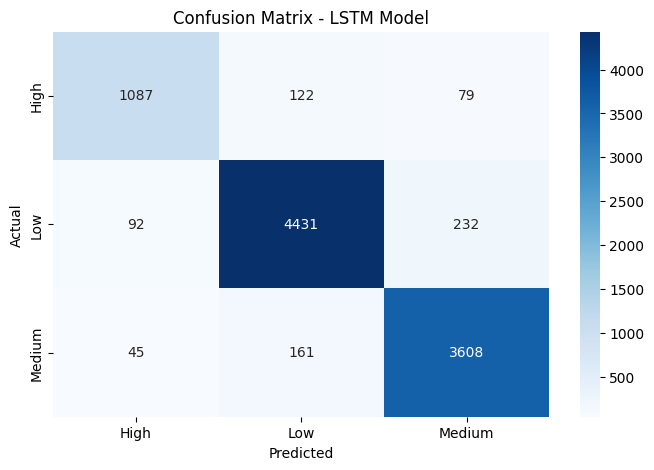


🏆 مقارنة النتائج النهائية:
Logistic Regression (ML): 0.9200 (92.00%)
LSTM (Deep Learning)     : 0.9258 (92.58%)
✅ LSTM أفضل من ML بنسبة 0.58%



In [ ]:
# ==================================================
# LSTM من البداية للنهاية - حل نهائي بدون أخطاء
# ==================================================

print("🚀 جاري تحميل المكتبات...")
import pandas as pd
import numpy as np
from datasets import load_dataset
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# تحميل أدوات NLTK
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

# ==========================================
# 1. تحميل البيانات من HuggingFace
# ==========================================
print("\n📥 جاري تحميل بيانات LEDGAR...")
dataset = load_dataset("coastalchp/ledgar", split='train')
df_raw = pd.DataFrame(dataset)
print(f"✅ تم تحميل {len(df_raw)} بند")

# ==========================================
# 2. Risk Mapping
# ==========================================
print("\n🏷️ جاري تحويل التصنيفات إلى High/Medium/Low...")

risk_mapping = {
    # High Risk
    49:'High',17:'High',81:'High',44:'High',27:'High',30:'High',36:'High',
    37:'High',23:'High',58:'High',88:'High',75:'High',62:'High',
    # Medium Risk
    47:'Medium',7:'Medium',20:'Medium',19:'Medium',43:'Medium',11:'Medium',
    10:'Medium',31:'Medium',42:'Medium',9:'Medium',16:'Medium',12:'Medium',
    15:'Medium',6:'Medium',4:'Medium',5:'Medium',21:'Medium',3:'Medium',
    51:'Medium',87:'Medium',85:'Medium',76:'Medium',98:'Medium',53:'Medium',
    80:'Medium',86:'Medium',99:'Medium',
    # Low Risk
    26:'Low',38:'Low',2:'Low',41:'Low',45:'Low',46:'Low',13:'Low',48:'Low',
    29:'Low',18:'Low',24:'Low',33:'Low',22:'Low',32:'Low',28:'Low',0:'Low',
    39:'Low',35:'Low',40:'Low',1:'Low',34:'Low',8:'Low',14:'Low',65:'Low',
    79:'Low',89:'Low',97:'Low',90:'Low',59:'Low',84:'Low',73:'Low',52:'Low'
}

df_raw['risk_level'] = df_raw['label'].map(risk_mapping)
df = df_raw.dropna(subset=['risk_level']).copy()
print(f"✅ بعد التصنيف: {len(df)} بند")

# ==========================================
# 3. تنظيف النصوص
# ==========================================
print("\n🧹 جاري تنظيف النصوص...")

def clean_text(text):
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    words = text.split()
    words = [lemmatizer.lemmatize(w) for w in words if w not in stop_words]
    return ' '.join(words)

df['cleaned_text'] = df['text'].apply(clean_text)

print(f"✅ توزيع الفئات:")
print(df['risk_level'].value_counts())

# ==========================================
# 4. تحضير البيانات لـ LSTM
# ==========================================
print("\n🔢 جاري تحويل النصوص إلى أرقام...")

X = df['cleaned_text'].values
y = df['risk_level'].values

# ترميز التصنيفات
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Tokenization
VOCAB_SIZE = 20000
MAX_LEN = 200

tokenizer = Tokenizer(num_words=VOCAB_SIZE)
tokenizer.fit_on_texts(X)
X_seq = tokenizer.texts_to_sequences(X)
X_pad = pad_sequences(X_seq, maxlen=MAX_LEN)

# تقسيم البيانات
X_train, X_test, y_train, y_test = train_test_split(
    X_pad, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"✅ تدريب: {len(X_train)} | اختبار: {len(X_test)}")

# ==========================================
# 5. بناء وتدريب LSTM
# ==========================================
print("\n🧠 جاري بناء نموذج LSTM...")

model = Sequential([
    Embedding(VOCAB_SIZE, 128, input_length=MAX_LEN),
    LSTM(128, dropout=0.3, recurrent_dropout=0.3),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(3, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

print("\n🚀 بدء التدريب (سيستغرق 5-10 دقائق)...")
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=5,
    batch_size=64,
    verbose=1
)

# ==========================================
# 6. النتائج
# ==========================================
print("\n📊 جاري تقييم النموذج...")
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
print(f"\n🎯 دقة LSTM: {accuracy:.4f} ({accuracy*100:.2f}%)")

print("\n📋 تقرير التصنيف:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# رسم Confusion Matrix
plt.figure(figsize=(8,5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - LSTM Model')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# ==========================================
# 7. المقارنة مع ML
# ==========================================
print("\n" + "="*50)
print("🏆 مقارنة النتائج النهائية:")
print(f"Logistic Regression (ML): 0.9200 (92.00%)")
print(f"LSTM (Deep Learning)     : {accuracy:.4f} ({accuracy*100:.2f}%)")
print("="*50)

# الفرق
diff = (accuracy - 0.92) * 100
if diff > 0:
    print(f"✅ LSTM أفضل من ML بنسبة {diff:.2f}%")
elif diff < 0:
    print(f"⚠️ ML أفضل من LSTM بنسبة {abs(diff):.2f}%")
else:
    print("🤝 النموذجان متساويان")
